In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

In [14]:
df = pd.read_csv("employee_turnover.csv")
# df.head()

In [15]:
X = df.drop("Employee_Turnover", axis=1)
y = df["Employee_Turnover"]

In [25]:
X_train , X_test , y_train, y_test = train_test_split(X , y , test_size=0.2, random_state=42)

In [17]:
Lr_model = LogisticRegression(max_iter=200)
Lr_model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,200
,multi_class,'deprecated'


In [19]:
#for lasso reg
lasso = LogisticRegression(penalty='l1', solver='liblinear', C=0.5)
lasso.fit(X_train, y_train)

,penalty,'l1'
,dual,False
,tol,0.0001
,C,0.5
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'liblinear'
,max_iter,100
,multi_class,'deprecated'


In [20]:
#fro ridge reg
ridge = LogisticRegression(penalty='l2', C=1, max_iter=200)
ridge.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,200
,multi_class,'deprecated'



Base
Accuracy: 0.8592592592592593
              precision    recall  f1-score   support

           0       0.85      0.90      0.87       145
           1       0.87      0.82      0.84       125

    accuracy                           0.86       270
   macro avg       0.86      0.86      0.86       270
weighted avg       0.86      0.86      0.86       270


Lasso
Accuracy: 0.8703703703703703
              precision    recall  f1-score   support

           0       0.86      0.90      0.88       145
           1       0.88      0.83      0.86       125

    accuracy                           0.87       270
   macro avg       0.87      0.87      0.87       270
weighted avg       0.87      0.87      0.87       270


Ridge
Accuracy: 0.8592592592592593
              precision    recall  f1-score   support

           0       0.85      0.90      0.87       145
           1       0.87      0.82      0.84       125

    accuracy                           0.86       270
   macro avg       0.

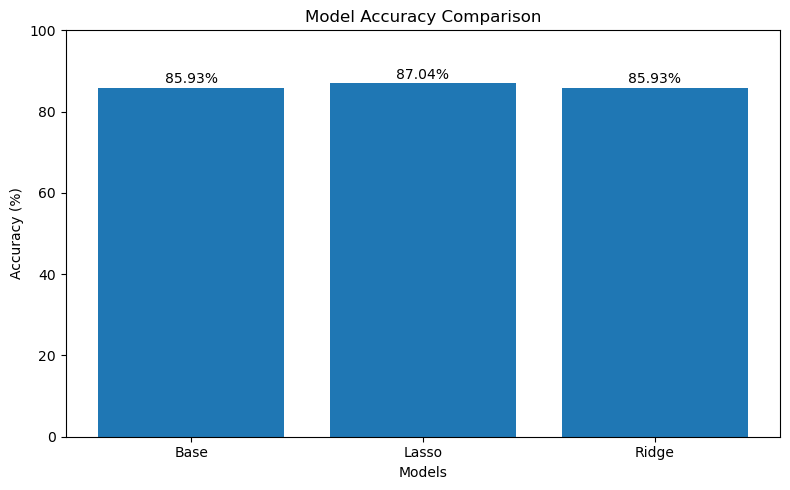

In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report

models = {
    'Base': Lr_model,
    'Lasso': lasso,
    'Ridge': ridge
}

model_names = []
accuracies = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    model_names.append(name)
    accuracies.append(accuracy * 100)

    print(f"\n{name}")
    print("Accuracy:", accuracy)
    print(classification_report(y_test, y_pred))

# Plot accuracy comparison
plt.figure(figsize=(8, 5))
plt.bar(model_names, accuracies)

plt.title('Model Accuracy Comparison')
plt.xlabel('Models')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)

# Display accuracy values above bars
for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f'{value:.2f}%', ha='center')

plt.tight_layout()
plt.show()